In [26]:
import pandas as pd
import numpy as numpy
import matplotlib as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.model_selection import train_test_split



## Preprocessing 

In [61]:
'''

Raw data
   ↓
Train/test split
   ↓
        ┌───────────────┐
Train → │ fit imputer   │
        │ fit scaler    │
        │ fit encoder   │
        └───────────────┘
                 ↓
          Transform train

Test → use the SAME fitted
       imputer/scaler/encoder
       ↓
       Transform test

'''

'\n\nRaw data\n   ↓\nTrain/test split\n   ↓\n        ┌───────────────┐\nTrain → │ fit imputer   │\n        │ fit scaler    │\n        │ fit encoder   │\n        └───────────────┘\n                 ↓\n          Transform train\n\nTest → use the SAME fitted\n       imputer/scaler/encoder\n       ↓\n       Transform test\n\n'

In [31]:
df_raw = pd.read_csv("data/diabetes_risk.csv")
df_raw.head()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


## Test train split

In [33]:
# need to drop patient_id
X = df_raw.drop(columns=["diabetes_risk", "patient_id"])
y = df_raw["diabetes_risk"]

In [46]:
X.head()

,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket
0,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High
1,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low
2,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low
3,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle
4,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High


In [47]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [48]:
X_train.head()

,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket
9839,28,Female,Indore,29.7,Yes,Sedentary,Non-Vegetarian,Current,Occasional,5.0,8,147,6.7,130,90,109.0,Middle
9680,54,Male,Patna,18.6,No,Active,Non-Vegetarian,Never,Occasional,8.0,7,162,7.0,133,80,91.4,Low
7093,49,Other,Thane,28.3,Yes,Moderate,Non-Vegetarian,Never,Never,6.8,2,161,6.6,140,80,107.3,Low
11293,34,Female,Chennai,20.6,Yes,Active,Pescatarian,Current,NaN,6.0,8,179,7.3,136,80,90.3,Middle
820,49,Male,Ahmedabad,21.0,No,Moderate,Non-Vegetarian,Never,Never,7.0,10,256,8.9,160,100,97.2,Low


## Preprocessing of Training Data

### Missing Values 
This time we may use simpleimpute as part of a Pipeline so it applies to all preprocessing. Will still create a missing category for the alcohol_consumption column

In [49]:
# Alchohol 
# Missing category column since over 20% of the data is missing
X_train['alcohol_consumption'] = X_train['alcohol_consumption'].fillna('Missing')
X_train.head()


,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket
9839,28,Female,Indore,29.7,Yes,Sedentary,Non-Vegetarian,Current,Occasional,5.0,8,147,6.7,130,90,109.0,Middle
9680,54,Male,Patna,18.6,No,Active,Non-Vegetarian,Never,Occasional,8.0,7,162,7.0,133,80,91.4,Low
7093,49,Other,Thane,28.3,Yes,Moderate,Non-Vegetarian,Never,Never,6.8,2,161,6.6,140,80,107.3,Low
11293,34,Female,Chennai,20.6,Yes,Active,Pescatarian,Current,Missing,6.0,8,179,7.3,136,80,90.3,Middle
820,49,Male,Ahmedabad,21.0,No,Moderate,Non-Vegetarian,Never,Never,7.0,10,256,8.9,160,100,97.2,Low


In [50]:
# Smoking, income bracket 
# Imputation using most frequent strategy, since less than 3% of the data is missing

for col in ['smoking_status', 'income_bracket']:
    imputer = SimpleImputer(strategy='most_frequent')
    X_train[col] = imputer.fit_transform(
        X_train[[col]]
    ).ravel()



#### Distribution checks

<Axes: xlabel='alcohol_consumption'>

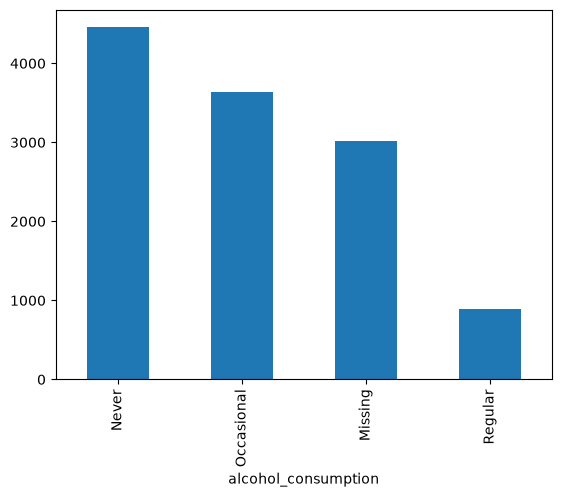

In [51]:
## Quick check of distributions
X_train['alcohol_consumption'].value_counts().plot(kind='bar')


<Axes: xlabel='smoking_status'>

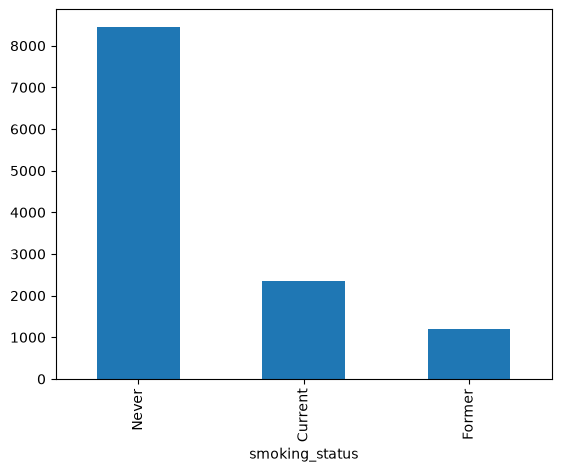

In [52]:
X_train['smoking_status'].value_counts().plot(kind='bar')


<Axes: xlabel='income_bracket'>

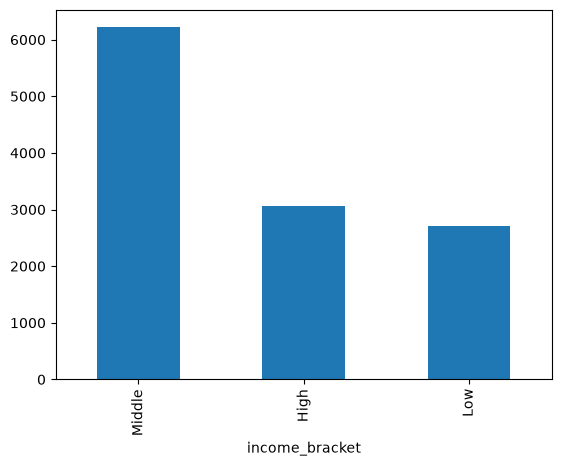

In [53]:
X_train['income_bracket'].value_counts().plot(kind='bar')


Looks similar to distributions from before missing values

### Scaling
Since the skew of each column is different, we can use different scaling methods for differe columns

- Numerical, not skewed: standardscaler
- Numerical, highly skewed: log transform to standard scaler
- Categorical, one hot/ordinal encoding


StandardScaler

Roughly normally distributed numerical features
Features without extreme outliers

RobustScaler

Numerical features with lots of outliers

MinMaxScaler

When you specifically want values constrained to a range such as 0–1
Sometimes useful for neural networks

No scaling

Tree-based models such as Random Forest, XGBoost, LightGBM
Scaling generally isn't necessary for these.


Distributions: (for scaling method)
Numerical
- age: slight left skew but not much (standard)
- bmi: left skew (robust/log transform then standard)
- hours_of_sleep: normal (standard)
- stress_level: normal (standard)
- fasting_blood_sugar: left skew (robust then standard)
- hba1c_level: left skew  (robust then standard)
- blood_pressure_systolic: normal (standard)
- blood_pressure_diastolic: normal (standard)
- waist_circumference_cm: slight left skew (standard)

Categorical: (for encoding)



In [54]:
# RobustScaler for skewed 
skewed_cols = ['bmi','fasting_blood_sugar','hba1c_level']

for col in skewed_cols:
    scaler = RobustScaler()
    X_train[col] = scaler.fit_transform(X_train[[col]])

In [55]:
# StandardScaler for all 
numeric_cols = X_train.select_dtypes(include="number").columns

scaler =  StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols]) 

In [56]:
X_train.head()

,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket
9839,-1.572261,Female,Indore,1.636491,Yes,Sedentary,Non-Vegetarian,Current,Occasional,-2.089821,0.950286,-0.571293,-0.215580,-0.757422,0.445908,0.813693,Middle
9680,0.924255,Male,Patna,-1.106673,No,Active,Non-Vegetarian,Never,Occasional,0.630041,0.485731,-0.179768,0.139837,-0.519640,-0.746891,-0.823355,Low
7093,0.444156,Other,Thane,1.290506,Yes,Moderate,Non-Vegetarian,Never,Never,-0.457904,-1.837045,-0.205870,-0.334053,0.035185,-0.746891,0.655569,Low
11293,-0.996142,Female,Chennai,-0.612409,Yes,Active,Pescatarian,Current,Missing,-1.183200,0.950286,0.263959,0.495254,-0.281858,-0.746891,-0.925671,Middle
820,0.444156,Male,Ahmedabad,-0.513556,No,Moderate,Non-Vegetarian,Never,Never,-0.276580,1.879397,2.273784,2.390813,1.620399,1.638708,-0.283874,Low


In [57]:
X_train.describe()

,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
count,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04
mean,7.105427e-17,-7.845576e-18,-1.539509e-16,-1.273056e-16,-2.250052e-17,1.894781e-17,-8.289665e-18,-4.263256e-16,-4.529710e-17
std,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00
min,-2.532460e+00,-1.996348e+00,-3.903062e+00,-2.301600e+00,-2.424507e+00,-2.466556e+00,-3.610808e+00,-4.325291e+00,-2.516212e+00
25%,-6.120627e-01,-7.112620e-01,-6.392280e-01,-9.079345e-01,-5.973942e-01,-6.894700e-01,-7.574220e-01,-7.468915e-01,-7.117385e-01
50%,6.007643e-02,-9.343232e-02,-2.765797e-01,2.117598e-02,-1.014635e-01,-9.710790e-02,3.518515e-02,2.073484e-01,-8.854400e-02
75%,7.322155e-01,6.232501e-01,6.300409e-01,4.857312e-01,5.249753e-01,4.952542e-01,8.277923e-01,4.459083e-01,6.276646e-01
max,3.420772e+00,4.379654e+00,4.256524e+00,1.879397e+00,6.032416e+00,7.722072e+00,4.790828e+00,4.024308e+00,4.459846e+00


In [58]:
categorical_cols = X_train.select_dtypes(include="object").columns

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_encoded = encoder.fit_transform(X_train[categorical_cols])

encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_cols,
    index=X_train.index
)

X_train = pd.concat(
    [X_train.drop(columns=categorical_cols), X_train_encoded],
    axis=1
)

C:\Users\XorsheedZanjani\AppData\Local\Temp\ipykernel_1520\506228273.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include="object").columns


In [59]:
X_train.head()

,age,bmi,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,gender_Female,...,smoking_status_Current,smoking_status_Former,smoking_status_Never,alcohol_consumption_Missing,alcohol_consumption_Never,alcohol_consumption_Occasional,alcohol_consumption_Regular,income_bracket_High,income_bracket_Low,income_bracket_Middle
9839,-1.572261,1.636491,-2.089821,0.950286,-0.571293,-0.215580,-0.757422,0.445908,0.813693,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
9680,0.924255,-1.106673,0.630041,0.485731,-0.179768,0.139837,-0.519640,-0.746891,-0.823355,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
7093,0.444156,1.290506,-0.457904,-1.837045,-0.205870,-0.334053,0.035185,-0.746891,0.655569,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
11293,-0.996142,-0.612409,-1.183200,0.950286,0.263959,0.495254,-0.281858,-0.746891,-0.925671,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
820,0.444156,-0.513556,-0.276580,1.879397,2.273784,2.390813,1.620399,1.638708,-0.283874,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [60]:
# Class imbalance: class is not too imbalanced for diabetes_risk

### Normalisation